In [18]:
# Climate_Change_Analysis.ipynb

# Imports Libs
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Import Data
notebook_dir = os.path.dirname(os.path.abspath("__file__"))
file_name = "Messstationen Monatsdaten v2 Datensatz_198501_202508.csv"
relative_path = os.path.join("..", "data", file_name)
csv_path = os.path.abspath(relative_path)

df = pd.read_csv(csv_path, parse_dates=["time"])

# Step 3: Preprocess
df["year"] = df["time"].dt.year
df["month"] = df["time"].dt.month

# Check for missing values
print(df.isnull().sum())
display(df.head(5))
display(df.tail(5))


time            0
station         0
absf_mittel     0
p               0
tl_i_mittel     0
tlmin           0
tlmax           0
so_h           18
tage_schreg     0
substation      0
year            0
month           0
dtype: int64


,time,station,absf_mittel,p,tl_i_mittel,tlmin,tlmax,so_h,tage_schreg,substation,year,month
0,1985-01-01 00:00:00+00:00,39,2.7,943.5,-7.9,-21.1,11.0,59.0,2.0,11801,1985,1
1,1985-02-01 00:00:00+00:00,39,3.7,951.4,-3.7,-13.9,12.7,103.0,3.0,11801,1985,2
2,1985-03-01 00:00:00+00:00,39,4.0,945.3,0.4,-6.0,19.6,130.0,2.0,11801,1985,3
3,1985-04-01 00:00:00+00:00,39,4.7,945.1,4.8,-1.7,23.5,181.0,4.0,11801,1985,4
4,1985-05-01 00:00:00+00:00,39,7.2,943.6,11.4,-0.9,29.0,217.0,0.0,11801,1985,5


,time,station,absf_mittel,p,tl_i_mittel,tlmin,tlmax,so_h,tage_schreg,substation,year,month
482,2025-03-01 00:00:00+00:00,39,4.6,943.6,4.0,-2.1,20.5,176.0,0.0,11803,2025,3
483,2025-04-01 00:00:00+00:00,39,5.8,944.3,8.2,-1.2,27.0,248.0,0.0,11803,2025,4
484,2025-05-01 00:00:00+00:00,39,7.3,944.7,10.9,5.8,31.8,158.0,0.0,11803,2025,5
485,2025-06-01 00:00:00+00:00,39,10.5,948.4,17.9,8.8,35.3,273.0,0.0,11803,2025,6
486,2025-07-01 00:00:00+00:00,39,10.9,945.6,16.0,9.6,35.6,149.0,0.0,11803,2025,7


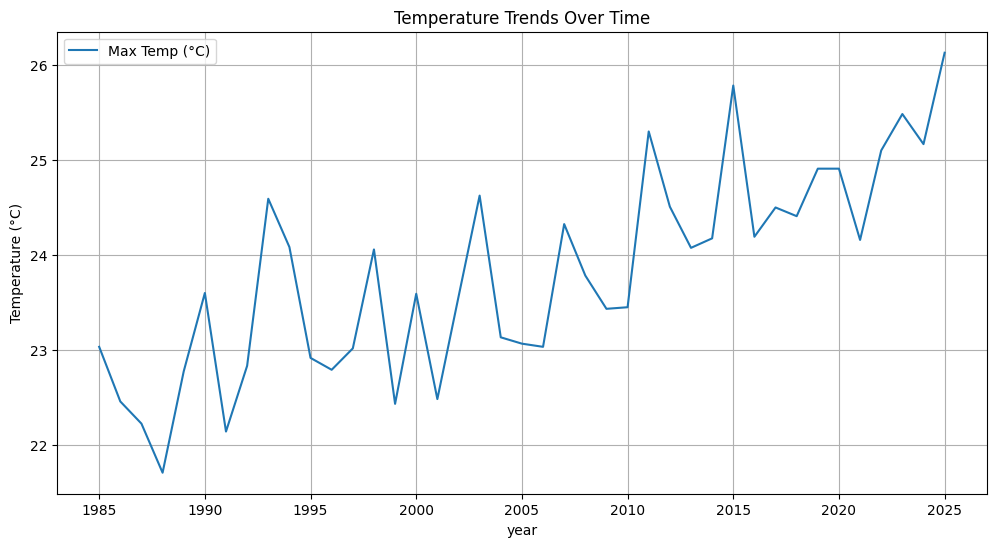

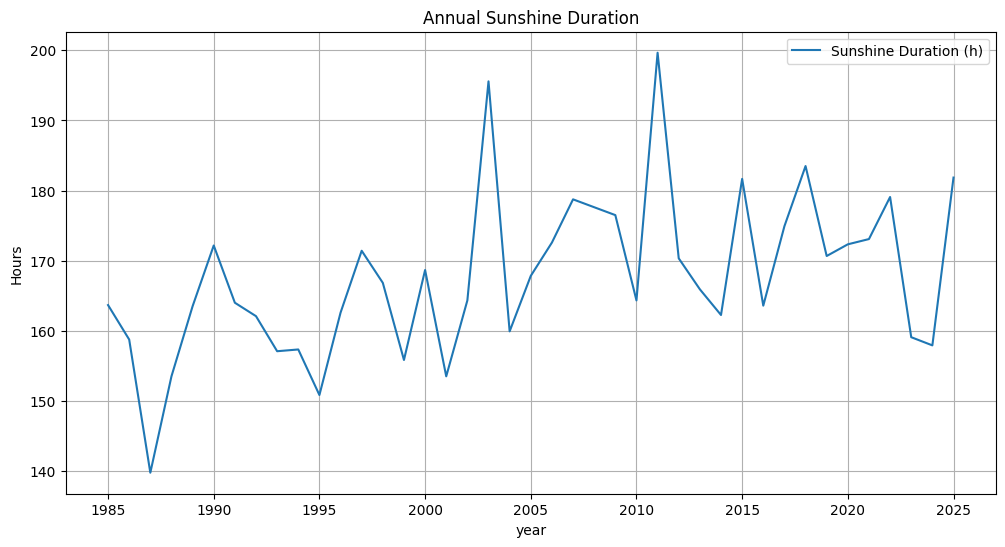

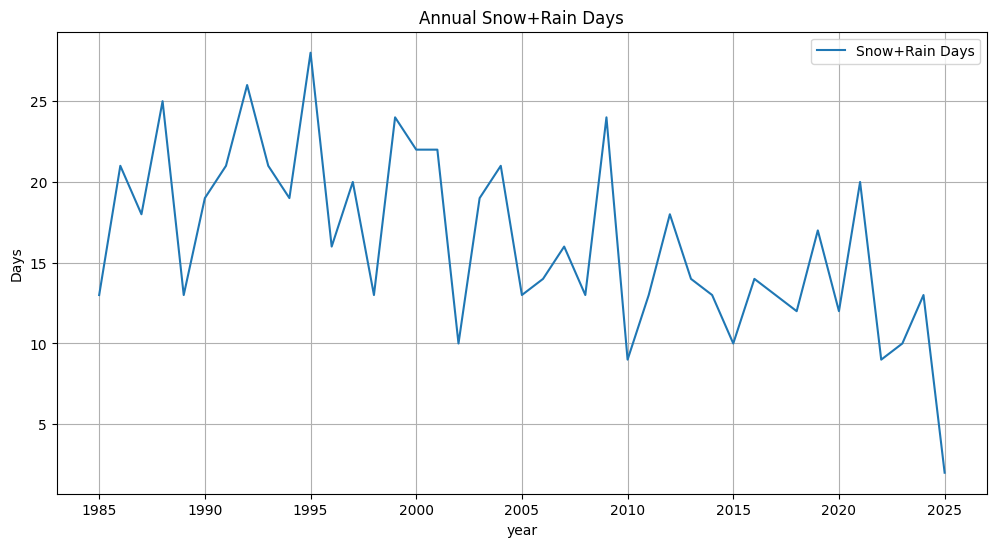

In [ ]:

# Annual Averages
# annual_avg = df.groupby("year")[["tl_i_mittel", "tlmin", "tlmax", "absf_mittel", "p", "so_h", "tage_schreg"]].mean().reset_index()

annual_avg = df.groupby("year")[["tl_i_mittel", "tlmin", "tlmax", "absf_mittel", "p", "so_h"]].mean()
annual_avg["tage_schreg"] = df.groupby("year")["tage_schreg"].sum()
annual_avg = annual_avg.reset_index()

# Plot Temperature Trends
plt.figure(figsize=(12,6))
# sns.lineplot(data=annual_avg, x="year", y="tl_i_mittel", label="Avg Temp (°C)")
sns.lineplot(data=annual_avg, x="year", y="tlmax", label="Max Temp (°C)")
# sns.lineplot(data=annual_avg, x="year", y="tlmin", label="Min Temp (°C)")
plt.title("Temperature Trends Over Time")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.legend()
plt.show()

# Sunshine Duration Trend
plt.figure(figsize=(12,6))
sns.lineplot(data=annual_avg, x="year", y="so_h", label="Sunshine Duration (h)")
plt.title("Annual Sunshine Duration")
plt.ylabel("Hours")
plt.grid(True)
plt.show()

# Snow+Rain Days Trend
snow_rain = df.groupby("year")["tage_schreg"].sum().reset_index()
plt.figure(figsize=(12,6))
sns.lineplot(data=snow_rain, x="year", y="tage_schreg", label="Snow+Rain Days")
plt.title("Annual Snow+Rain Days")
plt.ylabel("Days")
plt.grid(True)
plt.show()


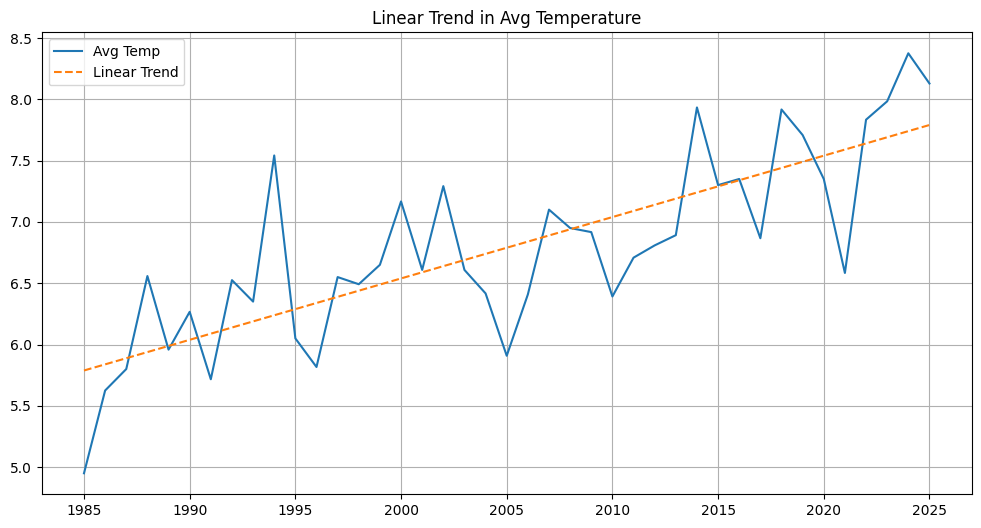

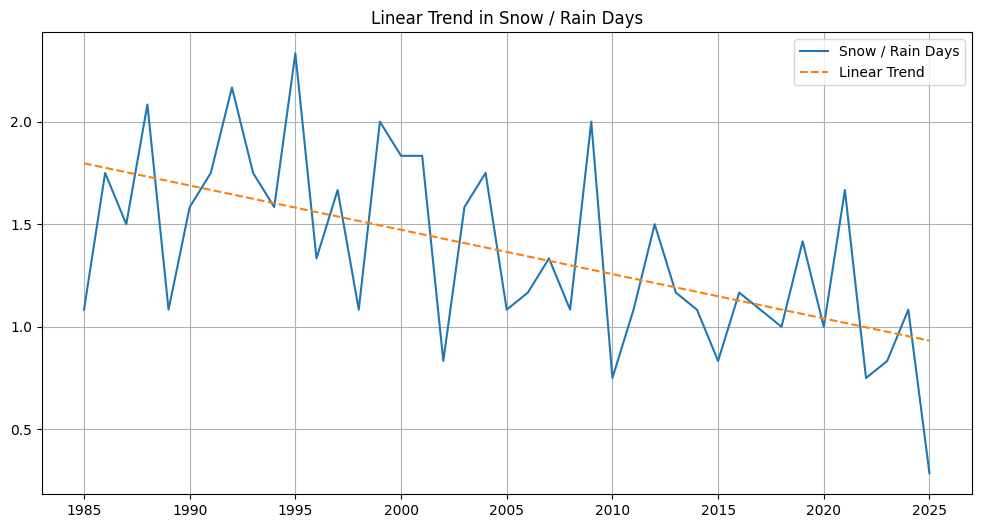

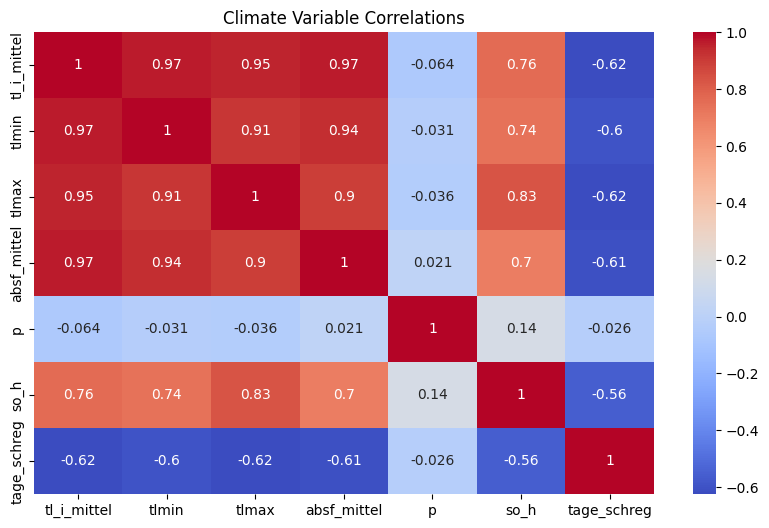

In [22]:
from sklearn.linear_model import LinearRegression
import numpy as np

# Linear Trend Analysis (Temperature)
X = annual_avg["year"].values.reshape(-1, 1)
y = annual_avg["tl_i_mittel"].values
model_temp = LinearRegression().fit(X, y)
trend_temp = model_temp.predict(X)

plt.figure(figsize=(12,6))
plt.plot(annual_avg["year"], y, label="Avg Temp")
plt.plot(annual_avg["year"], trend_temp, label="Linear Trend", linestyle="--")
plt.title("Linear Trend in Avg Temperature")
plt.legend()
plt.grid(True)
plt.show()

# Linear Trend Analysis (Snow and Rain)
X = annual_avg["year"].values.reshape(-1, 1)
y = annual_avg["tage_schreg"].values
model_sr = LinearRegression().fit(X, y)
trend_sr = model_sr.predict(X)

plt.figure(figsize=(12,6))
plt.plot(annual_avg["year"], y, label="Snow / Rain Days")
plt.plot(annual_avg["year"], trend_sr, label="Linear Trend", linestyle="--")
plt.title("Linear Trend in Snow / Rain Days")
plt.legend()
plt.grid(True)
plt.show()

# Correlation Matrix
plt.figure(figsize=(10,6))
sns.heatmap(df[["tl_i_mittel", "tlmin", "tlmax", "absf_mittel", "p", "so_h", "tage_schreg"]].corr(), annot=True, cmap="coolwarm")
plt.title("Climate Variable Correlations")
plt.show()